# Titanic · 02. Модели

В [01_eda](01_eda.ipynb) мы нашли признаки. Здесь отвечаем на вопросы:
1. **Как честно мерить?** Схема валидации, которой можно верить на 891 строке.
2. **С чем сравнивать?** Правила без ML — пол, «женщины и дети», правило по группам.
3. **Какая модель и почему?** Девять моделей от логистической регрессии до бустинга, с матчастью.
4. **Разница настоящая или шум?** Статистическое сравнение моделей.
5. **Что даёт каждая часть?** Абляция признаков, кривые обучения, ансамбль, калибровка.

Признаки берём из прод-модуля `kagglib.titanic.features` — тот же код потом поедет в артефакт.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.calibration import calibration_curve
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from kagglib.titanic import features as F

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA = "../../data/kaggle/titanic"
train = pl.read_csv(f"{DATA}/train.csv")
test = pl.read_csv(f"{DATA}/test.csv")
everyone = pl.concat([train.select("PassengerId", "Ticket"), test.select("PassengerId", "Ticket")])
y_all = train["Survived"].to_numpy()
print(f"признаков: {len(F.FEATURES)}")
print(F.FEATURES)

признаков: 21
('IsMale', 'Pclass', 'Title_Mr', 'Title_Mrs', 'Title_Miss', 'Title_Master', 'Title_Rare', 'Age', 'AgeMissing', 'IsChild', 'FamilySize', 'IsAlone', 'LargeFamily', 'TicketGroupSize', 'LogFarePerPerson', 'HasCabin', 'Emb_C', 'Emb_Q', 'Emb_S', 'GroupKnown', 'GroupSurvRate')


## 1. Схема валидации

**Почему не одна отложенная выборка.** Если отложить 20% (178 человек), стандартная ошибка accuracy
$\sqrt{p(1-p)/n} \approx \sqrt{0.8 \cdot 0.2 / 178} \approx 3$ п.п. Две модели с разницей в 2 п.п. будут меняться
местами от случайного разбиения.

**Что делаем:** `RepeatedStratifiedKFold` — 5 фолдов × 10 повторов = **50 оценок** на модель.
Стратификация держит долю выживших одинаковой в каждом фолде. Повторы усредняют удачу разбиения.

**Главное — признаки внутри фолда.** На каждом фолде:
- статистики заполнения (медиана возраста по титулу и т.д.) считаем **только по обучающей части**;
- «судьбу попутчиков» берём **только из обучающей части**: исходы валидации модель не видит ни прямо, ни через группу;
- размеры групп по билету считаем по всем 1309 пассажирам — это не таргет, такое знание честно есть и в проде.

Матрицы признаков для всех 50 фолдов считаем один раз и переиспользуем для всех моделей —
так все модели сравниваются **на одних и тех же разбиениях**, и сравнение можно делать попарно.

In [2]:
N_SPLITS, N_REPEATS = 5, 10
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=42)

t0 = time.time()
FOLDS = []
for tr_idx, va_idx in cv.split(np.zeros(len(y_all)), y_all):
    tr_df, va_df = train[tr_idx], train[va_idx]
    ctx = F.fold_context(tr_df, everyone)
    state = F.fit(tr_df, ctx)
    Xtr = F.transform(tr_df, state, ctx).select(F.FEATURES).to_pandas()
    Xva = F.transform(va_df, state, ctx).select(F.FEATURES).to_pandas()
    FOLDS.append((Xtr, y_all[tr_idx], Xva, y_all[va_idx], va_idx))
print(f"{len(FOLDS)} фолдов подготовлено за {time.time() - t0:.1f} с; train ≈ {len(FOLDS[0][1])}, valid ≈ {len(FOLDS[0][3])}")

50 фолдов подготовлено за 3.6 с; train ≈ 712, valid ≈ 179


In [3]:
RESULTS: dict[str, dict] = {}
OOF: dict[str, np.ndarray] = {}  # out-of-fold вероятности, усреднённые по повторам


def evaluate(name: str, model=None, rule=None, cols=None, store=True):
    """Прогоняет модель (или правило) по всем 50 фолдам. Возвращает accuracy по фолдам."""
    acc, ll, auc = [], [], []
    oof = np.zeros(len(y_all))
    t0 = time.time()
    for Xtr, ytr, Xva, yva, va_idx in FOLDS:
        if cols is not None:
            Xtr, Xva = Xtr[cols], Xva[cols]
        if rule is not None:
            p = rule(Xva).astype(float)
        else:
            m = clone(model).fit(Xtr, ytr)
            p = m.predict_proba(Xva)[:, 1]
        oof[va_idx] += p / N_REPEATS
        acc.append(accuracy_score(yva, p >= 0.5))
        if rule is None:
            ll.append(log_loss(yva, np.clip(p, 1e-6, 1 - 1e-6)))
            auc.append(roc_auc_score(yva, p))
    r = {"acc": np.array(acc), "logloss": np.mean(ll) if ll else np.nan, "auc": np.mean(auc) if auc else np.nan,
         "sec": time.time() - t0}
    if store:
        RESULTS[name], OOF[name] = r, oof
    print(f"{name:<28} acc {r['acc'].mean():.4f} ± {r['acc'].std():.4f}   "
          f"logloss {r['logloss']:.4f}   AUC {r['auc']:.4f}   ({r['sec']:.1f} c)")
    return r

## 2. Бейзлайны без ML

Прежде чем учить модели, фиксируем, что даёт здравый смысл. Если модель не обгоняет правило из одной строки —
она не нужна.

- **Все погибли** — нижняя граница.
- **Пол** — женщины выжили, мужчины нет.
- **Пол + мальчики** — плюс мальчики (титул Master) выжили: в EDA у них было 57%, так что правило должно помочь.
- **Пол + группа** — известное в Kaggle-сообществе правило «woman-child-group»: женщина погибает,
  если все её попутчики с известным исходом погибли; мальчик выживает, если все его попутчики выжили.
  Это ровно то, что мы увидели в EDA: группа поправляет пол там, где он ошибается.

In [4]:
evaluate("rule: все погибли", rule=lambda X: np.zeros(len(X)))
evaluate("rule: пол", rule=lambda X: X["IsMale"] == 0)
evaluate("rule: пол + мальчики", rule=lambda X: (X["IsMale"] == 0) | (X["Title_Master"] == 1))


def wcg_rule(X):
    female = X["IsMale"] == 0
    boy = X["Title_Master"] == 1
    known = X["GroupKnown"] > 0
    pred = female.copy()
    pred[female & known & (X["GroupSurvRate"] == 0)] = False   # вся группа погибла → и она тоже
    pred[boy & known & (X["GroupSurvRate"] == 1)] = True       # вся группа выжила → и мальчик тоже
    return pred


evaluate("rule: пол + группа (WCG)", rule=wcg_rule);

rule: все погибли            acc 0.6162 ± 0.0023   logloss nan   AUC nan   (0.1 c)


rule: пол                    acc 0.7868 ± 0.0313   logloss nan   AUC nan   (0.3 c)


rule: пол + мальчики         acc 0.7935 ± 0.0290   logloss nan   AUC nan   (0.2 c)


rule: пол + группа (WCG)     acc 0.8164 ± 0.0264   logloss nan   AUC nan   (0.4 c)


**Что видим.** «Пол + мальчики» чуть лучше пола (+0.7 п.п.): мальчиков всего 40, но больше половины из них выжили.
А **правило с группой** обгоняет пол на 3 п.п. — одна идея из EDA, никакой модели. Это и есть планка
(0.816), которую должны побить модели.

## 3. Модели и матчасть

### Логистическая регрессия
Модель: $P(y=1 \mid x) = \sigma(w^\top x + b)$, где $\sigma(z) = 1/(1+e^{-z})$.
Обучение — максимизация правдоподобия, то есть минимизация **log-loss**:
$$L(w) = -\sum_i \big[y_i \log p_i + (1-y_i)\log(1-p_i)\big] + \frac{1}{2C}\|w\|^2.$$
Градиент удивительно простой: $\nabla_w L = \sum_i (p_i - y_i)\,x_i + w/C$ — «ошибка × признак».
Функция выпуклая → один глобальный минимум, никакой случайности.

**Сильные стороны:** стабильна на малых данных, вероятности хорошо откалиброваны, веса интерпретируются
(каждый вес — изменение логарифма шансов). **Слабая:** видит только линейные эффекты. Взаимодействие
«пол × класс» (женщины 3-го класса — 50/50, а 1-го — 97%) она не поймает без явного признака.

### Дерево решений
Жадно делит данные по признаку и порогу, на каждом шаге максимально уменьшая **неоднородность Джини**
$G = 1 - \sum_k p_k^2$. Ловит взаимодействия бесплатно (сначала пол, потом внутри — класс), но
**высокая дисперсия**: чуть другие данные — другое дерево.

### Random Forest и Extra Trees — бэггинг
Много глубоких деревьев на бутстрэп-выборках и случайных подмножествах признаков, ответ — среднее.
Если у деревьев дисперсия $\sigma^2$ и попарная корреляция $\rho$, у среднего из $B$ деревьев:
$\operatorname{Var} = \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$. Случайность признаков снижает $\rho$ — в этом весь смысл.
Extra Trees ещё и пороги выбирает случайно: ещё меньше корреляция, чуть больше смещение.

### Градиентный бустинг (LightGBM, XGBoost, CatBoost)
Деревья строятся **последовательно**: каждое следующее аппроксимирует антиградиент функции потерь по
предсказаниям предыдущих — это градиентный спуск в пространстве функций: $F_m = F_{m-1} + \eta\, h_m$.
Снижает **смещение**, но на 700 строках легко переобучается — поэтому мелкие деревья, маленький шаг $\eta$
и регуляризация. Различия: LightGBM растит деревья по листьям (быстро, но жадно), XGBoost — по уровням с
регуляризацией весов листьев, CatBoost — симметричные деревья и упорядоченный бустинг против утечки таргета
(особенно хорош на малых данных).

### SVM и kNN
**SVM с RBF-ядром** ищет разделяющую поверхность с максимальным зазором в неявном бесконечномерном пространстве;
$C$ — штраф за ошибки, $\gamma$ — радиус влияния точки. **kNN** — голосование $k$ ближайших соседей.
Обоим нужны отмасштабированные признаки, иначе расстояние определяет признак с самым большим разбросом.

In [5]:
MODELS = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000)),
    "DecisionTree (d=4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=0),
    "RandomForest": RandomForestClassifier(n_estimators=500, max_depth=7, min_samples_leaf=2,
                                           max_features="sqrt", n_jobs=-1, random_state=0),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=500, max_depth=8, min_samples_leaf=2,
                                       max_features="sqrt", n_jobs=-1, random_state=0),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=15,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                               verbose=-1, random_state=0),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=2,
                             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=0, n_jobs=4),
    "CatBoost": CatBoostClassifier(iterations=500, learning_rate=0.03, depth=4, l2_leaf_reg=5,
                                   verbose=0, random_seed=0, thread_count=4),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=1.0, gamma="scale", probability=True, random_state=0)),
    "kNN (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, weights="distance")),
}
for name, m in MODELS.items():
    evaluate(name, m)

LogReg                       acc 0.8286 ± 0.0241   logloss 0.3979   AUC 0.8855   (3.4 c)


DecisionTree (d=4)           acc 0.8267 ± 0.0283   logloss 0.5102   AUC 0.8663   (1.2 c)


RandomForest                 acc 0.8313 ± 0.0228   logloss 0.3846   AUC 0.8876   (98.9 c)


ExtraTrees                   acc 0.8283 ± 0.0217   logloss 0.3902   AUC 0.8853   (69.2 c)


LightGBM                     acc 0.8416 ± 0.0174   logloss 0.3849   AUC 0.8921   (24.8 c)


XGBoost                      acc 0.8424 ± 0.0194   logloss 0.3816   AUC 0.8912   (14.9 c)


CatBoost                     acc 0.8384 ± 0.0217   logloss 0.3833   AUC 0.8904   (30.2 c)


SVM (RBF)                    acc 0.8311 ± 0.0236   logloss 0.4180   AUC 0.8699   (7.4 c)


kNN (k=15)                   acc 0.8132 ± 0.0230   logloss 0.7260   AUC 0.8633   (2.4 c)


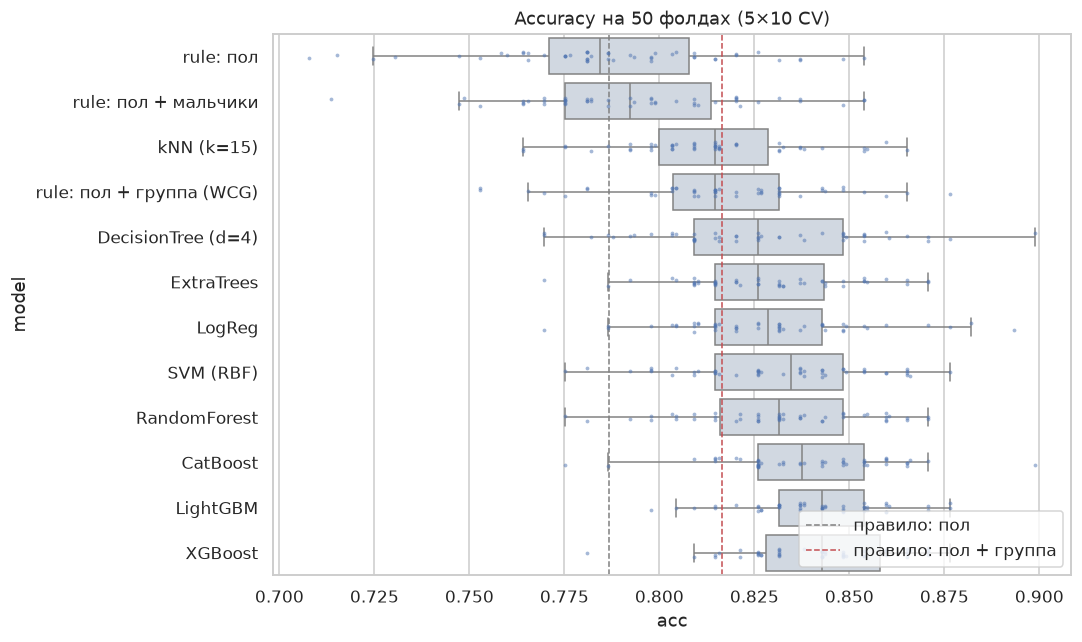

,acc,std,logloss,AUC,сек
XGBoost,0.8424,0.0194,0.3816,0.8912,14.8692
LightGBM,0.8416,0.0174,0.3849,0.8921,24.8480
CatBoost,0.8384,0.0217,0.3833,0.8904,30.2090
RandomForest,0.8313,0.0228,0.3846,0.8876,98.9401
SVM (RBF),0.8311,0.0236,0.4180,0.8699,7.3586
LogReg,0.8286,0.0241,0.3979,0.8855,3.3925
ExtraTrees,0.8283,0.0217,0.3902,0.8853,69.1729
DecisionTree (d=4),0.8267,0.0283,0.5102,0.8663,1.1936
rule: пол + группа (WCG),0.8164,0.0264,NaN,NaN,0.3507
kNN (k=15),0.8132,0.0230,0.7260,0.8633,2.4278


In [6]:
order = sorted(RESULTS, key=lambda k: RESULTS[k]["acc"].mean())
order = [k for k in order if k != "rule: все погибли"]
d = pd.DataFrame([(k, a) for k in order for a in RESULTS[k]["acc"]], columns=["model", "acc"])
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(d, y="model", x="acc", order=order, ax=ax, color="#cfd8e3", fliersize=0)
sns.stripplot(d, y="model", x="acc", order=order, ax=ax, size=2.5, alpha=0.5, color="#4c72b0")
ax.axvline(RESULTS["rule: пол"]["acc"].mean(), ls="--", c="gray", lw=1, label="правило: пол")
ax.axvline(RESULTS["rule: пол + группа (WCG)"]["acc"].mean(), ls="--", c="#c44e52", lw=1, label="правило: пол + группа")
ax.set_title("Accuracy на 50 фолдах (5×10 CV)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({k: {"acc": v["acc"].mean(), "std": v["acc"].std(), "logloss": v["logloss"], "AUC": v["auc"],
                            "сек": v["sec"]} for k, v in RESULTS.items()}).T.sort_values("acc", ascending=False)
summary.round(4)

## 4. Разница настоящая или шум?

Разброс по фолдам (±2–3 п.п.) больше, чем разница между лучшими моделями. Но фолды **общие** для всех моделей,
поэтому правильно смотреть на **попарную разницу на каждом фолде**: на трудном фолде проседают все модели сразу,
и эта общая часть шума вычитается.

**Ловушка:** обычный t-тест по 50 разностям врёт в сторону излишней уверенности. Обучающие части разных фолдов
пересекаются на ~60-80%, оценки **не независимы**. Поправка **Надо–Бенжио** (Nadeau & Bengio, 2003) расширяет дисперсию:
$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{test}}{n_{train}}\right)\hat\sigma_d^2}}, \qquad df = k - 1,$$
где $k = 50$ — число оценок, $n_{test}/n_{train} = 1/4$. Без поправки слагаемого $1/4$ нет, и при $k=50$ знаменатель
получается в ~3.7 раза меньше — «значимым» становится что угодно.

In [7]:
def corrected_ttest(a: np.ndarray, b: np.ndarray, ratio: float = 1 / (N_SPLITS - 1)):
    d = a - b
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + ratio) * d.var(ddof=1))
    t_naive = d.mean() / np.sqrt(d.var(ddof=1) / k)
    return d.mean(), 2 * stats.t.sf(abs(t), k - 1), 2 * stats.t.sf(abs(t_naive), k - 1)


ref = "rule: пол + группа (WCG)"
rows = [(k, *corrected_ttest(RESULTS[k]["acc"], RESULTS[ref]["acc"])) for k in RESULTS if k not in (ref, "rule: все погибли")]
cmp = pd.DataFrame(rows, columns=["модель", "Δacc к правилу WCG", "p (Надо–Бенжио)", "p (наивный)"]) \
        .sort_values("Δacc к правилу WCG", ascending=False)
cmp.round(4)

,модель,Δacc к правилу WCG,p (Надо–Бенжио),p (наивный)
7,XGBoost,0.0260,0.0296,0.0000
6,LightGBM,0.0253,0.0558,0.0000
8,CatBoost,0.0220,0.0688,0.0000
4,RandomForest,0.0149,0.1666,0.0000
9,SVM (RBF),0.0147,0.1678,0.0000
2,LogReg,0.0122,0.2957,0.0003
5,ExtraTrees,0.0119,0.2575,0.0001
3,DecisionTree (d=4),0.0103,0.4659,0.0095
10,kNN (k=15),-0.0032,0.7891,0.3280
1,rule: пол + мальчики,-0.0229,0.0309,0.0000


Сравни две колонки p-value: наивный тест объявит значимыми куда больше различий. Именно так на Kaggle рождается
«я улучшил CV на 0.3 п.п.», который потом не подтверждается на лидерборде.

## 5. Абляция: что даёт групповой признак

Уберём `GroupKnown` и `GroupSurvRate` и посмотрим, сколько теряет каждая модель.

LogReg без группы            acc 0.8273 ± 0.0232   logloss 0.4166   AUC 0.8731   (4.8 c)


RandomForest без группы      acc 0.8274 ± 0.0232   logloss 0.4001   AUC 0.8760   (105.1 c)


CatBoost без группы          acc 0.8319 ± 0.0220   logloss 0.3993   AUC 0.8783   (29.0 c)


SVM (RBF) без группы         acc 0.8269 ± 0.0229   logloss 0.4359   AUC 0.8580   (5.6 c)


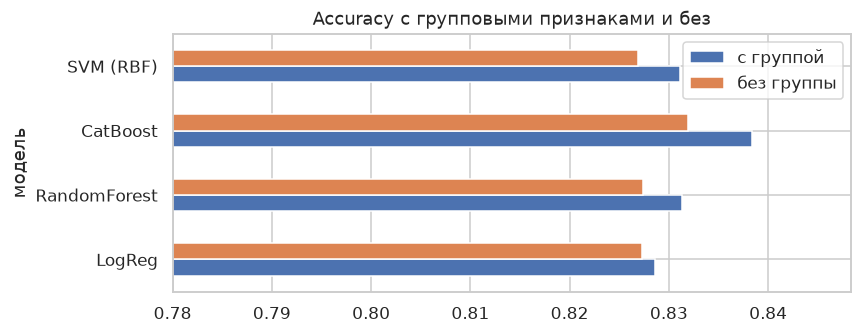

In [8]:
no_group = [c for c in F.FEATURES if c not in F.GROUP_FEATURES]
abl = []
for name in ["LogReg", "RandomForest", "CatBoost", "SVM (RBF)"]:
    r = evaluate(f"{name} без группы", MODELS[name], cols=no_group, store=False)
    abl.append((name, RESULTS[name]["acc"].mean(), r["acc"].mean()))
abl = pd.DataFrame(abl, columns=["модель", "с группой", "без группы"]).set_index("модель")
abl.plot.barh(figsize=(8, 3.2), xlim=(0.78, abl.values.max() + 0.01), title="Accuracy с групповыми признаками и без")
plt.tight_layout()
plt.show()

**Неожиданно:** без групповых признаков модели почти не теряют accuracy (LogReg −0.1 п.п., CatBoost −0.65 п.п.)
и всё равно на 4 п.п. обгоняют правило «пол». Значит, правило WCG (+3 п.п. к полу) и модели без групп ловят
**одну и ту же информацию разными путями**: размер группы по билету, размер семьи, класс и тариф уже почти
говорят, «большая бедная семья» это или нет — а такие семьи и погибали вместе.

Где групповые признаки всё-таки помогают — в **ранжировании**: AUC растёт на ~1.2 п.п. (LogReg 0.873 → 0.886,
CatBoost 0.878 → 0.890), logloss падает. То есть модель меньше ошибается в уверенности, даже если порог 0.5 это
почти не меняет. Мораль: признак, который сильно выглядит в EDA, может быть **избыточным** при наличии других.
Абляция — единственный способ это проверить.

## 6. Как думает дерево

Неглубокое дерево — модель, которую можно прочитать целиком. Посмотрим, какие правила оно нашло на всех данных.

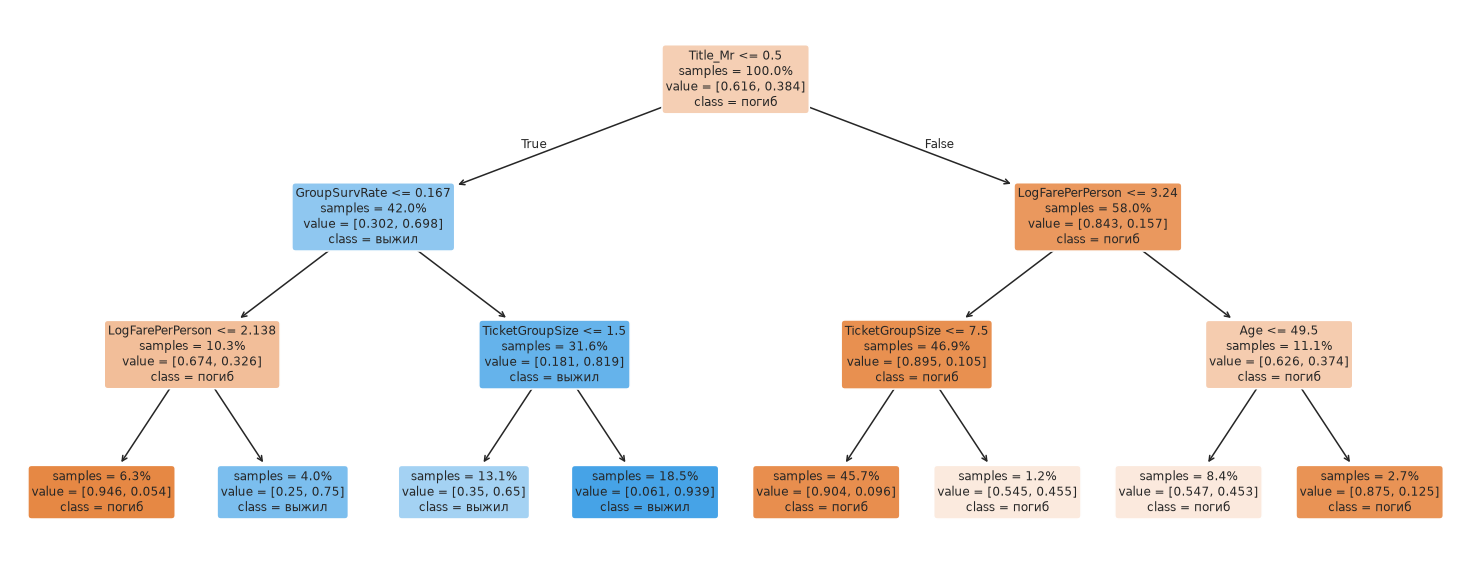

In [9]:
ctx_full = F.full_context(train, test)
state_full = F.fit(train, ctx_full)
X_full = F.transform(train, state_full, ctx_full).select(F.FEATURES).to_pandas()
# для иллюстрации обучаем на leave-one-out групповых признаках (себя transform исключает сам)
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=0).fit(X_full, y_all)
fig, ax = plt.subplots(figsize=(17, 6.5))
plot_tree(tree, feature_names=list(F.FEATURES), class_names=["погиб", "выжил"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=8, ax=ax)
plt.show()

Дерево само сформулировало «женщины и дети»: первый сплит — `Title_Mr`, то есть **«взрослый мужчина или нет»**
(женщины и мальчики Master — в одну сторону). Дальше:
- у женщин и детей — **судьба группы**: если попутчики в основном погибли (`GroupSurvRate ≤ 0.17`), выживает только треть;
  иначе — 82%, а у одиночек и малых групп — 94%;
- у взрослых мужчин — **тариф**: дорогой билет (1-й класс, хорошие каюты) поднимает шанс с 10% до 37%,
  а у них ещё и возраст: старше 50 — снова 12%.

Модель «понимает» задачу так же, как мы её поняли глазами в EDA.

## 7. Кривые обучения: смещение против дисперсии

Поможет ли больше данных? Обучим модели на растущей доле обучающей части и посмотрим accuracy на train и на валидации.
- Кривые **сходятся высоко** → данных хватает, модель упёрлась в информацию в признаках (смещение).
- **Большой зазор** между train и valid → модель запоминает (дисперсия), помогут данные или регуляризация.

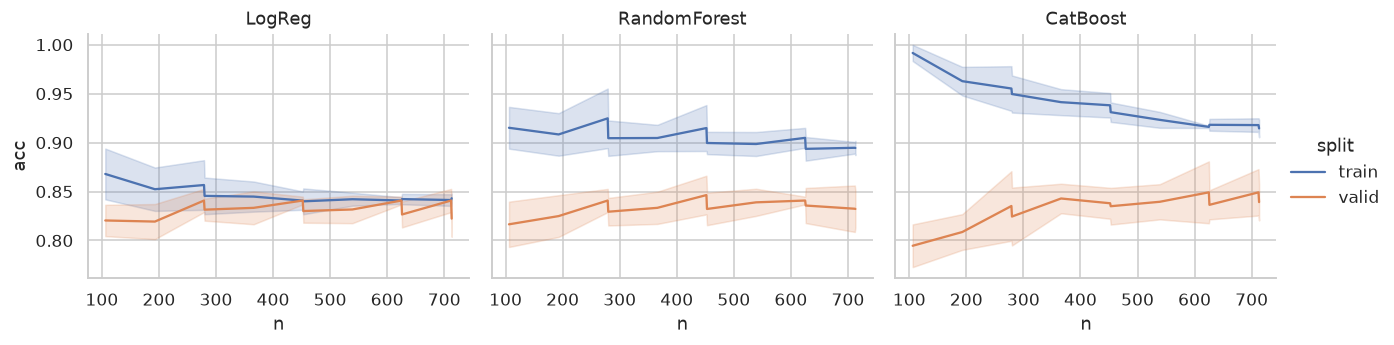

In [10]:
fracs = np.linspace(0.15, 1.0, 8)
lc_models = {"LogReg": MODELS["LogReg"], "RandomForest": MODELS["RandomForest"], "CatBoost": MODELS["CatBoost"]}
rng = np.random.default_rng(0)
lc = []
for Xtr, ytr, Xva, yva, _ in FOLDS[:10]:
    perm = rng.permutation(len(ytr))
    for f in fracs:
        idx = perm[: int(f * len(ytr))]
        for name, m in lc_models.items():
            mm = clone(m).fit(Xtr.iloc[idx], ytr[idx])
            lc.append((name, len(idx), "train", accuracy_score(ytr[idx], mm.predict(Xtr.iloc[idx]))))
            lc.append((name, len(idx), "valid", accuracy_score(yva, mm.predict(Xva))))
lc = pd.DataFrame(lc, columns=["model", "n", "split", "acc"])
g = sns.relplot(lc, x="n", y="acc", hue="split", col="model", kind="line", height=3.3, aspect=1.2, errorbar="sd")
g.set_titles("{col_name}")
plt.show()

- **LogReg**: train и valid сошлись уже к ~400 строкам на уровне ~0.84 — модели больше нечего учить, предел в её линейности
  (высокое смещение, низкая дисперсия).
- **RandomForest**: стабильный зазор ~6 п.п. — глубокие деревья частично запоминают выборку, а валидация почти не растёт.
- **CatBoost**: самая показательная картинка. На 100 строках train 0.99, valid 0.79 — чистое запоминание. С ростом данных
  train падает, valid растёт, зазор сокращается до ~7 п.п. и **ещё не закрылся** — CatBoost единственный, кому
  больше данных реально помогло бы.

**Вывод:** на Titanic выигрывает не сложная модель, а хорошие признаки. Дальше «крутить» гиперпараметры бустинга —
это подгонка под шум (±1.5 п.п. на LB).

## 8. Ансамбль

Идея: модели разной природы ошибаются на разных людях, и среднее их вероятностей лучше каждой
(та же формула дисперсии, что у леса: выигрыш зависит от корреляции $\rho$). Проверим, насколько модели разные.

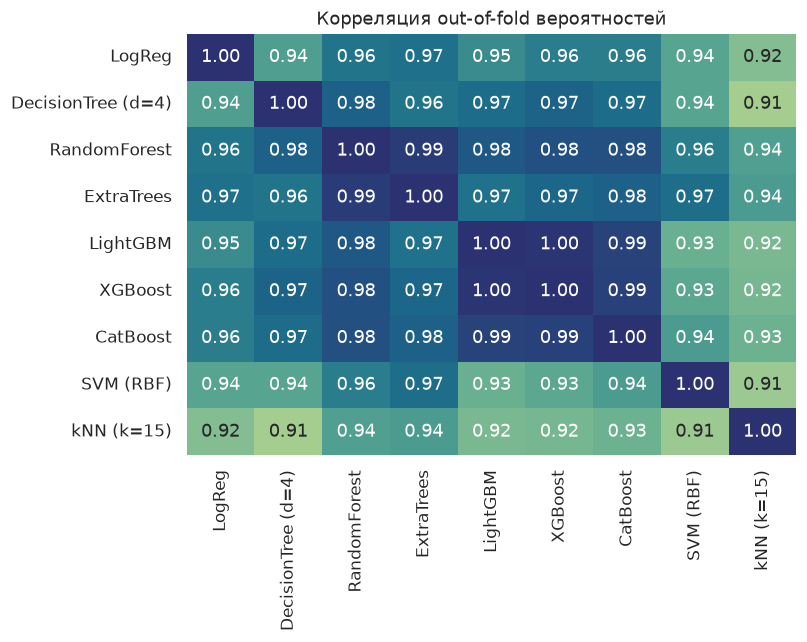

Ensemble (LR+RF+Cat+SVM)     acc 0.8337 ± 0.0239   logloss 0.3819   AUC 0.8927   (158.1 c)


Ensemble (LR+Cat)            acc 0.8345 ± 0.0247   logloss 0.3816   AUC 0.8931   (46.0 c)


,модель,Δacc к правилу WCG,p (Надо–Бенжио),p (наивный)
0,Ensemble (LR+RF+Cat+SVM),0.0173,0.0818,0.0000
1,Ensemble (LR+Cat),0.0181,0.0915,0.0000
2,CatBoost,0.0220,0.0688,0.0000
3,LogReg,0.0122,0.2957,0.0003


In [11]:
oof_df = pd.DataFrame({k: OOF[k] for k in MODELS})
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(oof_df.corr(), annot=True, fmt=".2f", cmap="crest", ax=ax, cbar=False)
ax.set_title("Корреляция out-of-fold вероятностей")
plt.tight_layout()
plt.show()


class SoftVote:
    """Среднее вероятностей нескольких моделей (sklearn-совместимо)."""

    def __init__(self, models):
        self.models = models

    def get_params(self, deep=False):
        return {"models": self.models}

    def set_params(self, **p):
        self.models = p["models"]
        return self

    def fit(self, X, y):
        self.fitted_ = [clone(m).fit(X, y) for m in self.models]
        return self

    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.fitted_], axis=0)
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


ENSEMBLE = SoftVote([MODELS["LogReg"], MODELS["RandomForest"], MODELS["CatBoost"], MODELS["SVM (RBF)"]])
evaluate("Ensemble (LR+RF+Cat+SVM)", ENSEMBLE)
ENSEMBLE_LC = SoftVote([MODELS["LogReg"], MODELS["CatBoost"]])
evaluate("Ensemble (LR+Cat)", ENSEMBLE_LC)
cmp_e = [(k, *corrected_ttest(RESULTS[k]["acc"], RESULTS[ref]["acc"])) for k in ["Ensemble (LR+RF+Cat+SVM)", "Ensemble (LR+Cat)", "CatBoost", "LogReg"]]
pd.DataFrame(cmp_e, columns=["модель", "Δacc к правилу WCG", "p (Надо–Бенжио)", "p (наивный)"]).round(4)

**Что видим.** Корреляция вероятностей между моделями 0.91–1.0 (LightGBM и XGBoost — практически одна модель).
При $\rho \approx 0.95$ усреднение почти ничего не даёт: ансамбль **не обогнал** CatBoost по accuracy (0.834 против 0.838),
но дал **лучший AUC** (0.893) и logloss — вероятности стали чуть аккуратнее. Все модели видят одни и те же признаки и
спотыкаются на одних и тех же людях; ансамбль не может исправить то, чего не знает ни одна модель.

## 9. Калибровка: можно ли верить вероятностям

Accuracy смотрит только на сторону порога 0.5. Но если модель говорит «70%», должны ли выживать 70% таких людей?
Это **калибровка**. Она важна, когда вероятности используются дальше: ранжирование, расчёт ожидаемых потерь, пороги.

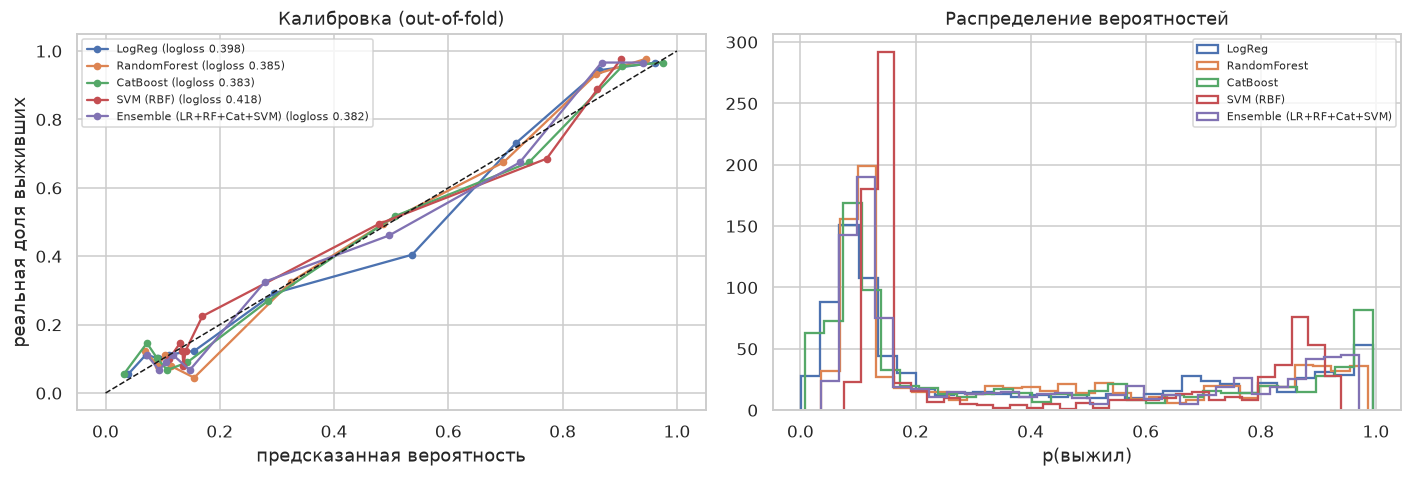

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k in ["LogReg", "RandomForest", "CatBoost", "SVM (RBF)", "Ensemble (LR+RF+Cat+SVM)"]:
    pt, pp = calibration_curve(y_all, OOF[k], n_bins=10, strategy="quantile")
    axes[0].plot(pp, pt, "o-", ms=4, label=f"{k} (logloss {RESULTS[k]['logloss']:.3f})")
    axes[1].hist(OOF[k], bins=30, histtype="step", lw=1.5, label=k)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="предсказанная вероятность", ylabel="реальная доля выживших", title="Калибровка (out-of-fold)")
axes[0].legend(fontsize=7)
axes[1].set(title="Распределение вероятностей", xlabel="p(выжил)")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

- Все модели **прилично откалиброваны**: точки близко к диагонали. Для логрега и бустинга это ожидаемо — они напрямую
  минимизируют log-loss. Заметное отклонение у логрега в середине (предсказывает ~0.55, а выживает 40%) — это
  нелинейность «женщины 3-го класса», которую линейная модель усредняет.
- **SVM** выдаёт вероятности не сам, а через отдельную калибровку Платта (сигмоида поверх расстояния до границы),
  поэтому его распределение «зубчатое»: высокий пик около 0.15 и около 0.85 — он почти не различает уверенность внутри классов.
  Отсюда и худший logloss при приличной accuracy.
- **Распределение бимодальное**: пик около 0.1 (взрослые мужчины 2-3 класса) и около 0.9-1.0 (женщины 1-2 класса),
  между ними — ровное «плато» сложных случаев. Именно на этом плато решается accuracy.

## 10. Итог и выбор прод-модели

In [13]:
final = pd.DataFrame({k: {"acc": v["acc"].mean(), "std": v["acc"].std(), "logloss": v["logloss"], "AUC": v["auc"]}
                      for k, v in RESULTS.items()}).T.sort_values("acc", ascending=False)
final.round(4)

,acc,std,logloss,AUC
XGBoost,0.8424,0.0194,0.3816,0.8912
LightGBM,0.8416,0.0174,0.3849,0.8921
CatBoost,0.8384,0.0217,0.3833,0.8904
Ensemble (LR+Cat),0.8345,0.0247,0.3816,0.8931
Ensemble (LR+RF+Cat+SVM),0.8337,0.0239,0.3819,0.8927
RandomForest,0.8313,0.0228,0.3846,0.8876
SVM (RBF),0.8311,0.0236,0.4180,0.8699
LogReg,0.8286,0.0241,0.3979,0.8855
ExtraTrees,0.8283,0.0217,0.3902,0.8853
DecisionTree (d=4),0.8267,0.0283,0.5102,0.8663


**Выбор для прода.** Смотрим не только на accuracy (разница между топом в пределах шума), но и на то, во что модель
превращается в проде:

| Кандидат | Качество | Перенос | Объяснимость |
|---|---|---|---|
| XGBoost / LightGBM | лучшие по accuracy (0.842) | ONNX через onnxmltools | SHAP |
| CatBoost | 0.838, −0.4 п.п. к лучшему — в пределах шума (std 2 п.п.) | нативный экспорт в ONNX **и в самодостаточный C++** | SHAP |
| LogReg | 0.829 | ONNX, или 21 вес + стандартизация — формула в любом языке | веса = вклад признаков |
| Ансамбль | 0.834, лучший AUC | несколько артефактов, сложнее поддерживать | хуже |

Разница между тремя бустингами — 0.4 п.п. при стандартном отклонении 2 п.п. и p-value между ними далеко от значимости.
Значит, выбираем по **прод-свойствам**: CatBoost умеет выгружать модель в C++ без единой зависимости, то есть в
бинарник, который встраивается куда угодно.

Берём **CatBoost как основную модель** и **LogReg как «резервную»** — она переносится буквально в одну формулу и
служит контрольной точкой: если в проде CatBoost и LogReg начинают сильно расходиться, это сигнал, что пришли данные
не такие, как в обучении. Что именно и почему они ошибаются — в [03_errors](03_errors.ipynb).

In [14]:
import os

os.makedirs("submissions", exist_ok=True)
X_te = F.transform(test, state_full, ctx_full).select(F.FEATURES).to_pandas()
X_tr = F.transform(train, state_full, ctx_full).select(F.FEATURES).to_pandas()
subs = {
    "rule_wcg": wcg_rule(X_te).astype(int).to_numpy(),
    "logreg": clone(MODELS["LogReg"]).fit(X_tr, y_all).predict(X_te),
    "catboost": clone(MODELS["CatBoost"]).fit(X_tr, y_all).predict(X_te),
    "ensemble": clone(ENSEMBLE).fit(X_tr, y_all).predict(X_te),
}
for k, p in subs.items():
    pl.DataFrame({"PassengerId": test["PassengerId"], "Survived": p.astype(int)}).write_csv(f"submissions/{k}.csv")
pd.DataFrame({k: [v.mean(), (v == subs["catboost"]).mean()] for k, v in subs.items()},
             index=["доля 'выжил' в test", "совпадение с CatBoost"]).round(3)

,rule_wcg,logreg,catboost,ensemble
доля 'выжил' в test,0.318,0.392,0.373,0.371
совпадение с CatBoost,0.897,0.919,1.000,0.945


## Мысли

1. **Две строки кода дают 80% результата.** Правило «пол + группа» — 0.816, лучшая модель — 0.842. Весь ML со всеми
   его бустингами добавил 2.6 п.п., и из них статистически значим (с поправкой) только лучший результат.
   На малых данных хороший признак стоит больше хорошей модели.
2. **Шум больше разницы.** Между топ-моделями десятые доли процента, а стандартное отклонение по фолдам — 2–3 п.п.
   Без попарного сравнения и поправки на зависимость фолдов легко «улучшить» модель случайностью.
   Это главный навык, который переносится в любые A/B-тесты.
3. **Сложность — не бесплатна.** Кривые обучения показывают: бустинг на малых выборках запоминает, логрег —
   стабилен с первой сотни строк. Разница между ними 1.4 п.п., и она незначима после поправки. В проде у простой модели огромные плюсы: переносимость, объяснимость, стабильность.
4. **Утечка прячется в признаках, а не в модели.** Групповой признак, посчитанный «по всем данным», дал бы фантастический
   CV. Только явный контекст «что мы знаем на момент предсказания» делает его честным — и это же контекст в проде.
5. **Избыточные признаки маскируются.** Групповой признак — самый яркий в EDA — почти не добавил accuracy, потому что
   его информацию модели уже собирают из размера группы, класса и тарифа. Абляция — обязательный шаг.
6. **Модели разной природы — не обязательно разные модели.** Корреляция вероятностей 0.91–1.0: на одних признаках
   логрег, лес и бустинг видят одно и то же. Ансамбль не исправит то, чего не знает ни одна модель. Кто эти люди — в 03_errors.